In [1]:
# Setup: base and fine-tuned Chronos-2
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import json

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import torch
from chronos import Chronos2Pipeline

BASE_MODEL = "amazon/chronos-2"
# Fine-tuned models: (local folder saved by TEP-Chronos2-FineTune.ipynb, Hugging Face repo with the same weights)
FINETUNED = {
    # 1 run (10k samples), r=32, lr 1e-4, best validation loss at step 200; not reported, weights not in this repo
    "Fine-tuned, 1 run": ("chronos-2-tep-sp-ctx2048-lora-final", "Imker0311/chronos-2-tep-sp-ctx2048-lora"),
    # 3 runs (20k samples), r=8, lr 2e-5, early stopping; the fine-tuned model in the article
    "Fine-tuned, 3 runs": ("chronos-2-tep-sp-3runs-ctx2048-lora-final", "Imker0311/chronos-2-tep-sp-3runs-ctx2048-lora"),
}
INCLUDE_1RUN = True   # False to score only the base and 3-run models

device = "cuda" if torch.cuda.is_available() else "cpu"
if not INCLUDE_1RUN:
    FINETUNED.pop("Fine-tuned, 1 run")
finetuned = {model: local if os.path.isdir(local) else hub for model, (local, hub) in FINETUNED.items()}
pipelines = {"Chronos-2": Chronos2Pipeline.from_pretrained(BASE_MODEL, device_map=device)}
for model, path in finetuned.items():   # LoRA adapters, merged onto the base model when loaded
    pipelines[model] = Chronos2Pipeline.from_pretrained(path, device_map=device,
                                                        import_allowlist=["chronos.chronos2.model"])
MODELS = list(pipelines)
MAX_CONTEXT = min(p.model_context_length for p in pipelines.values())
MAX_HORIZON = min(p.model_prediction_length for p in pipelines.values())
print(f"Loaded {', '.join(MODELS)} on {device}, fine-tuned weights from {', '.join(finetuned.values())}")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loaded Chronos-2, Fine-tuned, 1 run, Fine-tuned, 3 runs on cuda, fine-tuned weights from chronos-2-tep-sp-ctx2048-lora-final


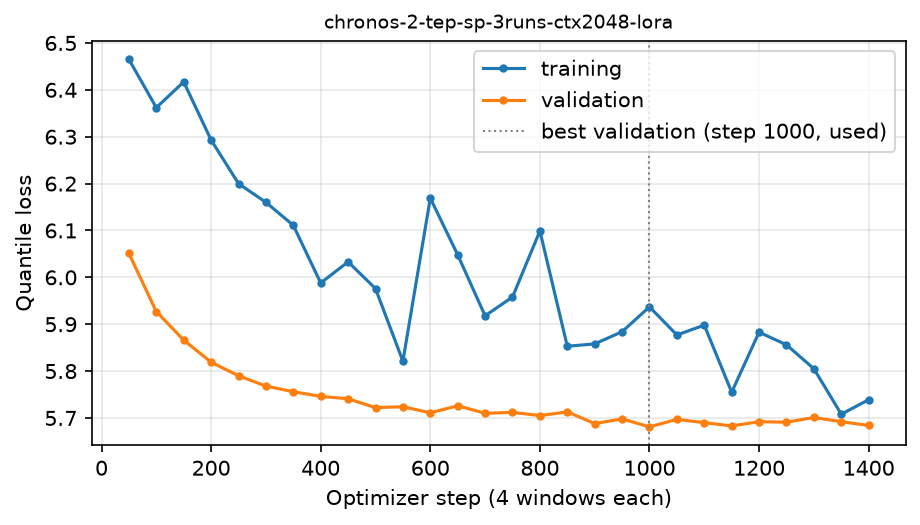

Best validation loss 5.681 at step 1000, run stopped at step 1400


In [2]:
# Training and validation loss of the fine-tune
import glob

RUN_DIR = "chronos-2-finetuned/chronos-2-tep-sp-3runs-ctx2048-lora"   # checkpoints written by TEP-Chronos2-FineTune.ipynb
log_file = f"{RUN_DIR}/log_history.json"   # whole run, when the checkpoints hold only part of it
if not os.path.exists(log_file):
    log_file = max(glob.glob(f"{RUN_DIR}/checkpoint-*/trainer_state.json"), key=os.path.getmtime)
history = json.load(open(log_file))["log_history"]
train_log = pd.DataFrame([h for h in history if "loss" in h])
val_log = pd.DataFrame([h for h in history if "eval_loss" in h])
best = val_log.loc[val_log["eval_loss"].idxmin()]

fig, ax = plt.subplots(figsize=(7, 3.5), dpi=150)
ax.plot(train_log["step"], train_log["loss"], marker="o", ms=3, label="training")
ax.plot(val_log["step"], val_log["eval_loss"], marker="o", ms=3, label="validation")
ax.axvline(best["step"], color="0.5", ls=":", lw=1, label=f"best validation (step {int(best['step'])}, used)")
ax.set_xlabel("Optimizer step (4 windows each)")
ax.set_title(RUN_DIR.split("/")[-1], fontsize=9)
ax.set_ylabel("Quantile loss")
ax.grid(alpha=0.3)
ax.legend()
os.makedirs("Figures", exist_ok=True)
fig.savefig("Figures/chronos2_finetune_loss.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Best validation loss {best['eval_loss']:.3f} at step {int(best['step'])}, run stopped at step "
      f"{int(val_log['step'].max())}")

In [3]:
# Load data
import json

DATA_FILE = "tep_sp_spaced_6min_noisy.h5"


def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


groups = {}
with h5py.File(DATA_FILE, "r") as f:
    time_h = f["t"][()] / 3600
    for key in ["xmeas", "xmv", "dist", "sp"]:
        groups[key] = (f[key][()], read_names(f[key]))
    if "y" in f:   # true valve positions
        groups["valve"] = (f["y"][:, 38:50], read_names(f["y"])[38:50])
    config = json.loads(f.attrs["config"])
SAMPLE_MIN = config["record_every"] / 60   # sampling interval (min)

nominal = {int(k): v for k, v in config["setpoints"].items()}
CHANGED = sorted({k for k, _, _ in config["setpoint_schedule"]})   # set points changed in this run
t_test = config.get("t_test")                                    # start of the test changes (h)

sp = groups["sp"][0]
off = {k: np.abs(sp[:, k - 1] - nominal[k]) > 1e-9 for k in CHANGED}
sp_change = np.zeros(len(time_h), dtype=int)
for k in reversed(CHANGED):
    sp_change[off[k]] = k

data = {"time_h": time_h, "sp_change": sp_change}
COLUMNS, LABELS = {}, {}
for group, (values, labels) in groups.items():
    COLUMNS[group] = [f"{group}_{i}" for i in range(1, values.shape[1] + 1)]
    for col, v, label in zip(COLUMNS[group], values.T, labels):
        data[col] = v
        LABELS[col] = label

df = pd.DataFrame(data)
df.insert(0, "item_id", "tep")
df.insert(1, "timestamp", pd.date_range("2026-01-01", periods=len(df), freq=f"{config['record_every']}s"))

TARGET_COLUMNS = COLUMNS["xmeas"] + COLUMNS["xmv"]
print(f"{len(df)} samples ({time_h[-1]:.0f} h), {len(TARGET_COLUMNS)} targets, covariate groups: "
      + ", ".join(f"{g} ({len(COLUMNS[g])})" for g in COLUMNS if g not in ["xmeas", "xmv"]))
print(f"changed set points: {CHANGED}, test part from {t_test} h")
df.head()

6798 samples (680 h), 53 targets, covariate groups: dist (12), sp (20), valve (12)
changed set points: [5, 7, 8, 11, 13, 14, 15, 17, 18, 19, 20], test part from 580.6 h


,item_id,timestamp,time_h,sp_change,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,...,valve_3,valve_4,valve_5,valve_6,valve_7,valve_8,valve_9,valve_10,valve_11,valve_12
0,tep,2026-01-01 00:00:00,0.1,0,0.250570,3646.911201,4529.162678,9.361743,26.955182,42.374646,...,24.683121,61.476138,22.362808,40.095187,38.413928,46.439184,47.490184,40.948926,17.063033,50.0
1,tep,2026-01-01 00:06:00,0.2,0,0.251641,3685.782817,4532.305731,9.392197,27.192827,42.306830,...,24.669825,61.220980,22.282045,39.990620,38.834873,46.076364,47.465945,40.781658,19.495237,50.0
2,tep,2026-01-01 00:12:00,0.3,0,0.224798,3649.568095,4485.146695,9.372377,26.672050,42.430624,...,21.892922,61.453199,22.133312,40.754288,37.087577,47.823150,47.578868,40.150284,16.873578,50.0
3,tep,2026-01-01 00:18:00,0.4,0,0.218406,3639.328339,4472.573385,9.490855,26.897409,42.106486,...,21.619293,61.542878,22.350442,40.748417,34.570768,46.721658,47.682376,40.822785,17.567854,50.0
4,tep,2026-01-01 00:24:00,0.5,0,0.259690,3665.940633,4583.163603,9.290618,27.026282,42.238532,...,25.661680,61.170016,21.863833,42.083198,38.107019,48.403660,47.805239,40.148750,18.059470,50.0


In [4]:
# Test events and forecast windows
events = []   # (start index, end index, set point, new value)
for k in CHANGED:
    on = off[k]
    for i in range(len(on)):
        if on[i] and (i == 0 or not on[i - 1]):
            start = i
        if on[i] and (i == len(on) - 1 or not on[i + 1]):
            events.append((start, i, k, sp[start, k - 1]))
events.sort()

BUFFER = 20   # nominal samples before the event at the start of each forecast

# One forecast per test event, from BUFFER samples before the event up to the start of the next event
rows = []
for n, (s, e, k, v) in enumerate(events):
    if t_test is None or time_h[s] < t_test:
        continue
    split = max(s - BUFFER, 0)
    end = events[n + 1][0] if n + 1 < len(events) else len(df)
    if end <= e:
        raise ValueError(f"event {n} is still running when the next event starts")
    horizon = min(end - split, MAX_HORIZON)
    rows.append({
        "event": n,
        "set point": f"SP {k} {LABELS[f'sp_{k}']}",
        "change (%)": 100 * (v - nominal[k]) / nominal[k],
        "start (h)": time_h[split],
        "horizon (h)": horizon * SAMPLE_MIN / 60,
        "split": split,
        "horizon": horizon,
    })
windows = pd.DataFrame(rows).set_index("event")

EXCLUDED = []   # test events left out of the scores
windows = windows.drop(EXCLUDED)
print(f"{len(windows)} test events")
windows.round(2)

11 test events


,set point,change (%),start (h),horizon (h),split,horizon
event,,,,,,
66,SP 11 Stripper underflow (m3/h),1.74,578.6,10.9,5785,109
67,SP 5 Recycle flow (kscmh),-1.86,587.5,8.9,5874,89
68,SP 14 Reactor feed D (mol%),2.91,594.4,12.3,5943,123
69,SP 20 Product E (mol%),-7.18,604.7,12.8,6046,128
70,SP 18 Reactor temperature (C),0.62,615.5,6.5,6154,65
71,SP 15 Reactor feed E (mol%),-3.99,620.0,12.1,6199,121
72,SP 13 Reactor feed A (mol%),-1.86,630.1,12.8,6300,128
73,SP 17 Reactor level (%),-1.67,640.9,10.0,6408,100
74,SP 19 Purge B (mol%),7.23,648.9,12.8,6488,128


In [5]:
# Covariates and scored variables
COVARIATES = [f"sp_{k}" for k in CHANGED]   # changed set points, known over the forecast (as in the fine-tune)
CONTEXTS = [2048, None]                     # 2048 = fine-tuning context, None = all available history

EXCLUDED_VARIABLES = ["xmeas_37"]   # Product D, about 0.017 mol%: near zero, so its percentage error explodes
SCORED = [c for c in COLUMNS["xmeas"] if c not in EXCLUDED_VARIABLES]   # measurements only, no valves
SCALE = df[SCORED].std()    # standard deviation over the whole dataset
print(f"covariates ({len(COVARIATES)}): {', '.join(COVARIATES)}")

covariates (11): sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15, sp_17, sp_18, sp_19, sp_20


In [6]:
# Metrics
QUANTILES = [0.1, 0.5, 0.9]
ALPHA = round(1 - (QUANTILES[-1] - QUANTILES[0]), 6)   # 0.2 for the 10-90% interval
METRICS = ["scaled MAE", "MAPE (%)", "coverage", "scaled Winkler"]


def winkler(actual, lower, upper, alpha):
    """Winkler interval score at every step."""
    width = upper - lower
    below = width + 2 / alpha * (lower - actual)
    above = width + 2 / alpha * (actual - upper)
    return np.where(actual < lower, below, np.where(actual > upper, above, width))


def score_event(forecast, truth_df):
    """Metrics per scored variable for one forecast, forecast[col] = (point forecast, lower, upper)."""
    rows = {}
    for col in SCORED:
        pred, lower, upper = forecast[col]
        actual = truth_df[col].to_numpy()
        rows[col] = {
            "scaled MAE": np.mean(np.abs(pred - actual)) / SCALE[col],
            "MAPE (%)": 100 * np.mean(np.abs(actual - pred) / np.abs(actual)),
            "coverage": np.mean((actual >= lower) & (actual <= upper)),
            "scaled Winkler": np.mean(winkler(actual, lower, upper, ALPHA)) / SCALE[col],
        }
    return pd.DataFrame(rows).T

In [7]:
# Forecast of one window
def run_forecast(pipeline, context_df, truth_df):
    window_df = pd.concat([context_df, truth_df])
    used = [c for c in COVARIATES if window_df[c].nunique() > 1]   # constant covariates carry no information
    pred_df = pipeline.predict_df(
        context_df[["item_id", "timestamp"] + TARGET_COLUMNS + used],
        future_df=truth_df[["item_id", "timestamp"] + used] if used else None,
        prediction_length=len(truth_df),
        quantile_levels=QUANTILES,
        id_column="item_id",
        timestamp_column="timestamp",
        target=TARGET_COLUMNS,
    )
    forecast = {}
    for col in TARGET_COLUMNS:
        sub = pred_df[pred_df["target_name"] == col]
        forecast[col] = (sub["predictions"].to_numpy(), sub[str(QUANTILES[0])].to_numpy(),
                         sub[str(QUANTILES[-1])].to_numpy())
    return forecast

In [8]:
# Forecast every test event with both models at every context length
rows = []
for model, pipeline in pipelines.items():
    for context in CONTEXTS:
        label = "max" if context is None else str(context)
        for n, w in windows.iterrows():
            split, horizon = int(w["split"]), int(w["horizon"])
            context_used = min(split, MAX_CONTEXT) if context is None else context
            context_df = df.iloc[split - context_used:split]
            truth_df = df.iloc[split:split + horizon]
            scores = score_event(run_forecast(pipeline, context_df, truth_df), truth_df).mean()
            rows.append({"model": model, "context": label, "event": n, **scores[METRICS]})
        means = pd.DataFrame(rows[-len(windows):])[METRICS].mean()
        print(f"{model:21s} context {label:>4}: " + ", ".join(f"{m} {means[m]:.3f}" for m in METRICS))
results = pd.DataFrame(rows)

Chronos-2             context 2048: scaled MAE 0.536, MAPE (%) 2.358, coverage 0.805, scaled Winkler 2.435


Chronos-2             context  max: scaled MAE 0.514, MAPE (%) 2.248, coverage 0.812, scaled Winkler 2.304


Fine-tuned, 1 run     context 2048: scaled MAE 0.517, MAPE (%) 2.268, coverage 0.688, scaled Winkler 2.430


Fine-tuned, 1 run     context  max: scaled MAE 0.499, MAPE (%) 2.192, coverage 0.669, scaled Winkler 2.319


Fine-tuned, 3 runs    context 2048: scaled MAE 0.517, MAPE (%) 2.261, coverage 0.729, scaled Winkler 2.387


Fine-tuned, 3 runs    context  max: scaled MAE 0.494, MAPE (%) 2.138, coverage 0.724, scaled Winkler 2.243


In [9]:
# Scaled MAE and scaled Winkler per event
per_event = results.pivot_table(index="event", columns=["context", "model"], values=["scaled MAE", "scaled Winkler"],
                                sort=False)
per_event.index = [f"{n}: {windows.loc[n, 'set point']}" for n in per_event.index]
per_event.round(3)

scaled MAE                              \
context                                   2048       max              2048   
model                                Chronos-2 Chronos-2 Fine-tuned, 1 run   
66: SP 11 Stripper underflow (m3/h)      0.594     0.555             0.606   
67: SP 5 Recycle flow (kscmh)            0.482     0.469             0.574   
68: SP 14 Reactor feed D (mol%)          0.461     0.445             0.459   
69: SP 20 Product E (mol%)               0.434     0.430             0.470   
70: SP 18 Reactor temperature (C)        0.637     0.507             0.591   
71: SP 15 Reactor feed E (mol%)          0.598     0.582             0.584   
72: SP 13 Reactor feed A (mol%)          0.444     0.450             0.441   
73: SP 17 Reactor level (%)              0.586     0.612             0.507   
74: SP 19 Purge B (mol%)                 0.583     0.561             0.521   
75: SP 7 Separator level (%)             0.510     0.500             0.460   
76: SP 8 Stripper level (%)              0.572     0.545             0.471   

                                                                          \
context                                           max               2048   
model                               Fine-tuned, 1 run Fine-tuned, 3 runs   
66: SP 11 Stripper underflow (m3/h)             0.568              0.622   
67: SP 5 Recycle flow (kscmh)                   0.541              0.557   
68: SP 14 Reactor feed D (mol%)                 0.465              0.434   
69: SP 20 Product E (mol%)                      0.474              0.453   
70: SP 18 Reactor temperature (C)               0.533              0.632   
71: SP 15 Reactor feed E (mol%)                 0.562              0.609   
72: SP 13 Reactor feed A (mol%)                 0.425              0.419   
73: SP 17 Reactor level (%)                     0.480              0.491   
74: SP 19 Purge B (mol%)                        0.506              0.522   
75: SP 7 Separator level (%)                    0.445              0.466   
76: SP 8 Stripper level (%)                     0.490              0.483   

                                                       scaled Winkler  \
context                                            max           2048   
model                               Fine-tuned, 3 runs      Chronos-2   
66: SP 11 Stripper underflow (m3/h)              0.585          2.511   
67: SP 5 Recycle flow (kscmh)                    0.519          2.212   
68: SP 14 Reactor feed D (mol%)                  0.434          2.075   
69: SP 20 Product E (mol%)                       0.458          2.035   
70: SP 18 Reactor temperature (C)                0.507          3.132   
71: SP 15 Reactor feed E (mol%)                  0.594          2.751   
72: SP 13 Reactor feed A (mol%)                  0.407          2.008   
73: SP 17 Reactor level (%)                      0.491          2.643   
74: SP 19 Purge B (mol%)                         0.511          2.557   
75: SP 7 Separator level (%)                     0.452          2.336   
76: SP 8 Stripper level (%)                      0.473          2.521   

                                                                 \
context                                   max              2048   
model                               Chronos-2 Fine-tuned, 1 run   
66: SP 11 Stripper underflow (m3/h)     2.350             2.961   
67: SP 5 Recycle flow (kscmh)           2.170             2.839   
68: SP 14 Reactor feed D (mol%)         2.055             2.034   
69: SP 20 Product E (mol%)              2.001             2.095   
70: SP 18 Reactor temperature (C)       2.249             3.043   
71: SP 15 Reactor feed E (mol%)         2.636             2.798   
72: SP 13 Reactor feed A (mol%)         2.043             1.957   
73: SP 17 Reactor level (%)             2.712             2.427   
74: SP 19 Purge B (mol%)                2.466             2.383   
75: SP 7 Separator level (%)            2.244      

In [10]:
# Average and standard deviation over all test events
summary = results.groupby(["context", "model"], sort=False)[METRICS].mean()
summary_std = results.groupby(["context", "model"], sort=False)[METRICS].std()
print(f"Mean ± std over {len(windows)} test events and {len(SCORED)} measurements ({DATA_FILE})")
summary.round(3).astype(str) + " ± " + summary_std.round(3).astype(str)

Mean ± std over 11 test events and 40 measurements (tep_sp_spaced_6min_noisy.h5)


,,scaled MAE,MAPE (%),coverage,scaled Winkler
context,model,,,,
2048,Chronos-2,0.536 ± 0.072,2.358 ± 0.369,0.805 ± 0.065,2.435 ± 0.345
max,Chronos-2,0.514 ± 0.061,2.248 ± 0.356,0.812 ± 0.052,2.304 ± 0.238
2048,"Fine-tuned, 1 run",0.517 ± 0.062,2.268 ± 0.292,0.688 ± 0.053,2.43 ± 0.41
max,"Fine-tuned, 1 run",0.499 ± 0.047,2.192 ± 0.226,0.669 ± 0.042,2.319 ± 0.294
2048,"Fine-tuned, 3 runs",0.517 ± 0.077,2.261 ± 0.367,0.729 ± 0.064,2.387 ± 0.499
max,"Fine-tuned, 3 runs",0.494 ± 0.058,2.138 ± 0.272,0.724 ± 0.059,2.243 ± 0.352


In [11]:
# Save scores
RESULTS_FILE = f"Results/FineTune_chronos2_{os.path.splitext(DATA_FILE)[0]}.h5"

os.makedirs("Results", exist_ok=True)
with h5py.File(RESULTS_FILE, "w") as f:
    f.attrs["settings"] = json.dumps({"data_file": DATA_FILE, "finetuned": finetuned, "buffer": BUFFER,
                                      "quantiles": QUANTILES, "covariates": COVARIATES, "excluded_events": EXCLUDED,
                                      "excluded_variables": EXCLUDED_VARIABLES})
    f.create_dataset("event", data=windows.index.to_numpy())
    for (context, model), table in results.groupby(["context", "model"], sort=False):
        for name in METRICS:
            f.create_dataset(f"{model}/context_{context}/per_event/{name}", data=table[name].to_numpy())
            f.create_dataset(f"{model}/context_{context}/average/{name}", data=table[name].mean())
            f.create_dataset(f"{model}/context_{context}/std/{name}", data=table[name].std())
print(f"Saved scores to {RESULTS_FILE}")

Saved scores to Results/FineTune_chronos2_tep_sp_spaced_6min_noisy.h5


In [12]:
# Summary: ARX baseline, base and fine-tuned Chronos-2
# ARX + Ridge from Loop_TEP-ARX-SetpointForecast.ipynb on the same data, events, covariates and scored measurements
ARX_FILE = "Results/Loop_setpointforecast_arx_noisy_sp.h5"
SUMMARY_MODELS = ["Chronos-2", "Fine-tuned, 3 runs"]

with h5py.File(ARX_FILE, "r") as f:
    arx_settings = json.loads(f.attrs["settings"])
    assert arx_settings["data_file"] == DATA_FILE and list(f["event"][()]) == list(windows.index)
    assert [c for c in arx_settings["covariates"] if c not in arx_settings["past_only"]] == COVARIATES
    assert arx_settings["scored"] == SCORED
    arx = pd.DataFrame({name: f[f"per_event/{name}"][()] for name in METRICS})

rows = [(context, model) for context in ["2048", "max"] for model in SUMMARY_MODELS]
names = {"Fine-tuned, 3 runs": "Chronos-2 fine-tuned", "max": "all history"}
index = pd.MultiIndex.from_tuples([("ARX + Ridge", "trained on history")]
                                  + [(names.get(m, m), names.get(c, c)) for c, m in rows], names=["model", "context"])
table_mean = pd.DataFrame([arx.mean()] + [summary.loc[r] for r in rows], index=index)[METRICS]
table_std = pd.DataFrame([arx.std()] + [summary_std.loc[r] for r in rows], index=index)[METRICS]
print(f"Mean ± std over {len(windows)} test events and {len(SCORED)} measurements ({DATA_FILE}), "
      "set points as covariates")
table_mean.round(3).astype(str) + " ± " + table_std.round(3).astype(str)

Mean ± std over 11 test events and 40 measurements (tep_sp_spaced_6min_noisy.h5), set points as covariates


,,scaled MAE,MAPE (%),coverage,scaled Winkler
model,context,,,,
ARX + Ridge,trained on history,0.521 ± 0.057,2.353 ± 0.263,0.801 ± 0.054,2.33 ± 0.185
Chronos-2,2048,0.536 ± 0.072,2.358 ± 0.369,0.805 ± 0.065,2.435 ± 0.345
Chronos-2 fine-tuned,2048,0.517 ± 0.077,2.261 ± 0.367,0.729 ± 0.064,2.387 ± 0.499
Chronos-2,all history,0.514 ± 0.061,2.248 ± 0.356,0.812 ± 0.052,2.304 ± 0.238
Chronos-2 fine-tuned,all history,0.494 ± 0.058,2.138 ± 0.272,0.724 ± 0.059,2.243 ± 0.352


Event 68: Chronos-2 scaled MAE 0.476, Fine-tuned, 3 runs scaled MAE 0.452


,description,scaled MAE (Chronos-2),"scaled MAE (Fine-tuned, 3 runs)",improvement
xmeas_19,Stripper steam flow (kg/h),0.497,0.270,0.227
xmeas_34,Purge F (mol%),0.557,0.342,0.215
xmeas_11,Separator temperature (C),0.234,0.216,0.018
xmeas_21,Reactor CW outlet temp (C),0.434,0.430,0.005
xmeas_7,Reactor pressure (kPa),0.309,0.306,0.004
xmeas_6,Reactor feed rate (kscmh),0.622,0.633,-0.011


Shown: xmeas_19, xmeas_34, xmeas_11, xmeas_21


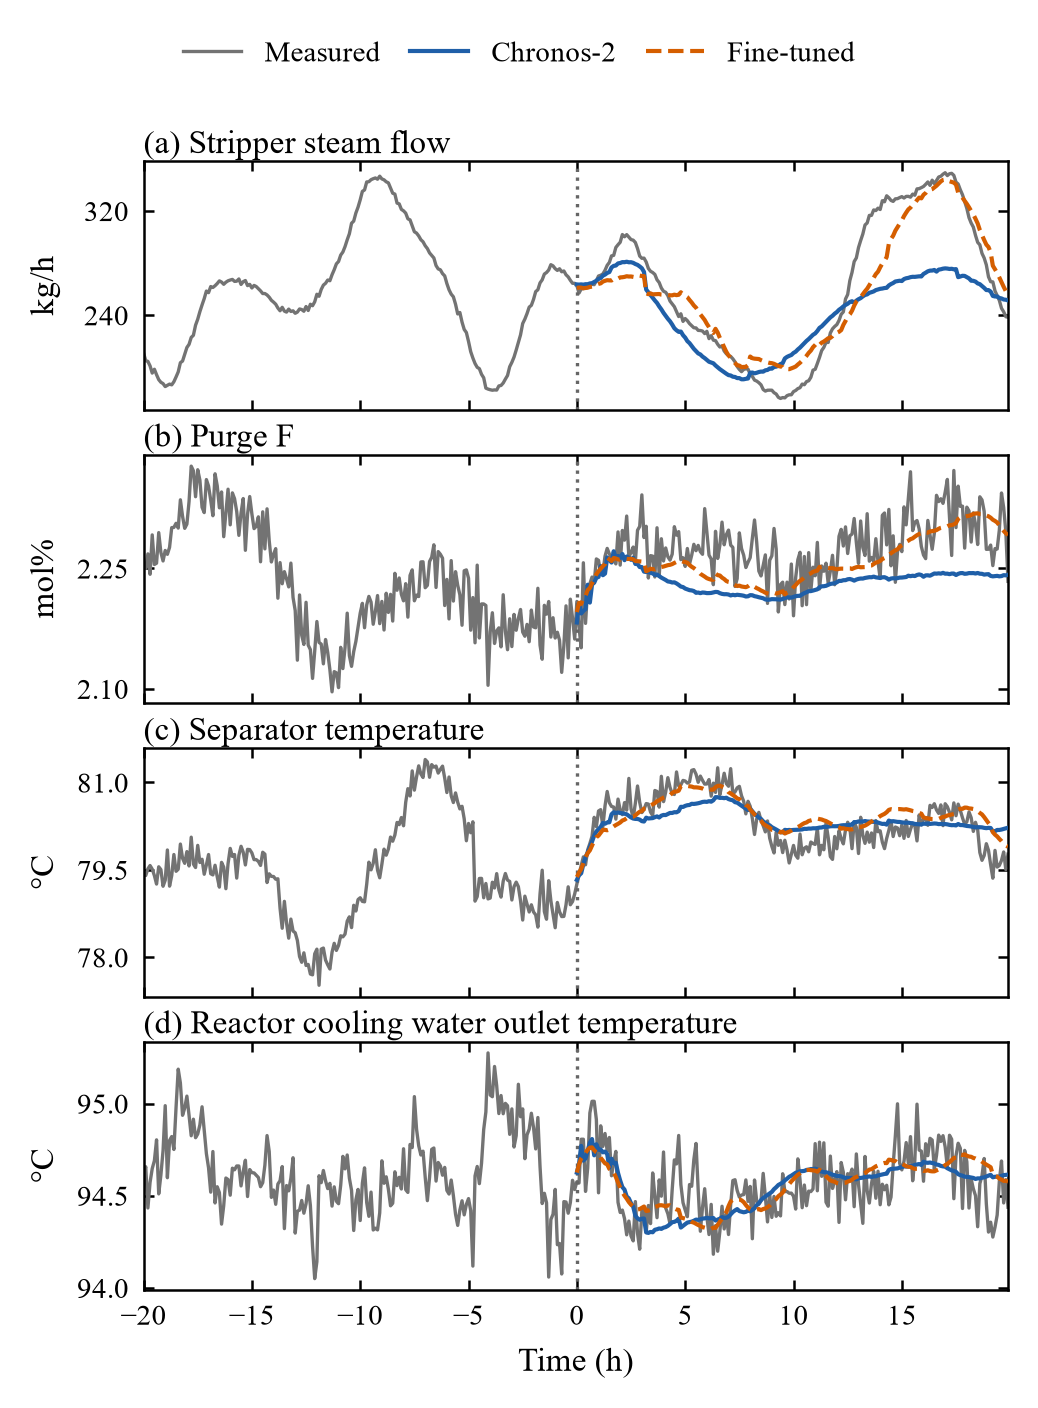

Saved Figures/chronos2_finetune_article.pdf and .png


In [13]:
# Article figure: base and fine-tuned Chronos-2 at one event, measurements chosen by the improvement
import re
from matplotlib.legend_handler import HandlerTuple
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

EVENT_INDEX = 68
HORIZON = 200
FIGURE_CONTEXT = 2048   # context of both forecasts, None = all available history
PLOT_LEAD_IN = 200      # context samples shown
FIGURE_MODELS = ["Chronos-2", "Fine-tuned, 3 runs"]   # base, fine-tuned
FIGURE_LABELS = {"Fine-tuned, 3 runs": "Fine-tuned"}   # legend names, where they differ from the model names
FIXED_COLUMNS = ["xmeas_19", "xmeas_34"]                  # stripper steam flow, purge F
OTHER_COLUMNS = ["xmeas_6", "xmeas_7", "xmeas_21", "xmeas_11"]   # measurements of the other article figures
N_OTHER = 2             # of OTHER_COLUMNS, those with the largest improvement
FIGURE_DIR = "Figures"
SHOW_INTERVALS = False  # shade the 10-90% interval of each forecast in the colour of its line
INTERVAL_ALPHA = 0.2
FIGURE_NAME = "chronos2_finetune_article" + ("_intervals" if SHOW_INTERVALS else "")
MODEL_COLORS = ["#1f5fa8", "#d55e00"]   # base, fine-tuned
MODEL_LINESTYLES = ["-", "--"]
ARTICLE_STYLE = {
    "figure.dpi": 300,   # sharp figure in the notebook, the saved files use dpi=600
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
}


def split_label(label):
    match = re.fullmatch(r"(.*?)\s*\((.*)\)", label)
    if match is None:
        return label, ""
    name, unit = match.groups()
    name = re.sub(r" temp$", " temperature", name.replace("CW", "cooling water"))
    return name, {"C": "°C", "m3/h": "m³/h"}.get(unit, unit)


split = int(windows.loc[EVENT_INDEX, "split"])
context_df = df.iloc[split - (min(split, MAX_CONTEXT) if FIGURE_CONTEXT is None else FIGURE_CONTEXT):split]
truth_df = df.iloc[split:split + HORIZON]
lead = df.iloc[split - PLOT_LEAD_IN:split]
figure_forecasts = {model: run_forecast(pipelines[model], context_df, truth_df) for model in FIGURE_MODELS}
print(f"Event {EVENT_INDEX}: " + ", ".join(
    f"{model} scaled MAE {score_event(fc, truth_df)['scaled MAE'].mean():.3f}" for model, fc in figure_forecasts.items()))

# Improvement of the fine-tuned model per measurement
base, tuned = FIGURE_MODELS
mae = pd.DataFrame({model: score_event(figure_forecasts[model], truth_df)["scaled MAE"] for model in FIGURE_MODELS})
ranking = pd.DataFrame({
    "description": [LABELS[col] for col in SCORED],
    f"scaled MAE ({base})": mae[base],
    f"scaled MAE ({tuned})": mae[tuned],
    "improvement": mae[base] - mae[tuned],
}, index=SCORED)
others = ranking.loc[OTHER_COLUMNS].sort_values("improvement", ascending=False)
ARTICLE_COLUMNS = FIXED_COLUMNS + list(others.index[:N_OTHER])   # or a fixed list of columns
display(ranking.loc[FIXED_COLUMNS + list(others.index)].round(3))
print(f"Shown: {', '.join(ARTICLE_COLUMNS)}")

t0 = truth_df["time_h"].iloc[0]   # forecast start becomes time 0
measured_t = np.concatenate([lead["time_h"], truth_df["time_h"]]) - t0
forecast_t = truth_df["time_h"].to_numpy() - t0
with plt.rc_context(ARTICLE_STYLE):
    fig, axes = plt.subplots(len(ARTICLE_COLUMNS), 1, figsize=(3.5, 1.1 * len(ARTICLE_COLUMNS)), sharex=True)
    for letter, ax, col in zip("abcdefgh", axes, ARTICLE_COLUMNS):
        name, unit = split_label(LABELS[col])
        ax.plot(measured_t, np.concatenate([lead[col], truth_df[col]]), color="0.45", lw=0.8, label="Measured")
        for model, color, ls in zip(FIGURE_MODELS, MODEL_COLORS, MODEL_LINESTYLES):
            ax.plot(forecast_t, figure_forecasts[model][col][0], color=color, ls=ls, lw=1.0, zorder=3,
                    label=FIGURE_LABELS.get(model, model))
            if SHOW_INTERVALS:
                _, lower, upper = figure_forecasts[model][col]
                ax.fill_between(forecast_t, lower, upper, color=color, alpha=INTERVAL_ALPHA, lw=0, zorder=2)
        ax.axvline(0, color="0.4", ls=":", lw=0.8)
        ax.set_title(f"({letter}) {name}", loc="left", pad=2)
        ax.set_ylabel(unit)
        ax.yaxis.set_major_locator(MaxNLocator(3))
        ax.ticklabel_format(axis="y", useOffset=False)
        ax.margins(x=0)
    axes[-1].set_xlabel("Time (h)")
    fig.align_ylabels(axes)
    handles, labels = axes[0].get_legend_handles_labels()
    if SHOW_INTERVALS:   # each forecast line drawn over a patch of its interval colour
        handles = handles[:1] + [(Patch(color=color, alpha=INTERVAL_ALPHA, lw=0), h)
                                 for color, h in zip(MODEL_COLORS, handles[1:])]
    fig.tight_layout(h_pad=0.3)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(labels), frameon=False,
               handlelength=2.0, columnspacing=1.0, handler_map={tuple: HandlerTuple(ndivide=1, pad=0)})

    os.makedirs(FIGURE_DIR, exist_ok=True)
    for ext in ["pdf", "png"]:
        fig.savefig(f"{FIGURE_DIR}/{FIGURE_NAME}.{ext}", dpi=600, bbox_inches="tight")
    plt.show()
print(f"Saved {FIGURE_DIR}/{FIGURE_NAME}.pdf and .png")